# Previsão de Taxas de Mortalidade — AutoARIMA vs Prophet

Comparação metodológica entre **AutoARIMA** (statsforecast 2.0.3) e **Prophet** 1.3.0 para previsão
de séries anuais de taxa de mortalidade, com dados reais do SIM para SP, RJ e MG (2015–2022).

- **Janela de treinamento:** 2015–2020 (6 observações por série)
- **Janela de validação:** 2021–2022 (2 observações)
- **Horizonte de previsão:** 2023–2025 (3 anos à frente)
- **Métricas:** MASE (Mean Absolute Scaled Error) e SMAPE (Symmetric Mean Absolute Percentage Error)

**Datas:** todas as séries utilizam `YYYY-12-31` com `freq='YE'` para evitar deslocamento de ano
(um erro comum que desloca as previsões em um ano).

> **Fonte dos dados:** recorte real do SIM/DataSUS (óbitos por município de residência) para
> SP, RJ e MG, agregado por município × ano × grupo CID-10 × sexo × faixa etária em
> `data/notebooks/sim_agregado.parquet`. O arquivo é gerado por
> `scripts/build_notebook_extract.py` a partir dos arquivos brutos do DataSUS, e as contagens
> batem com os microdados. População: estimativas IBGE/TCU
> (`backend/seeds/data/tcu_populacao.csv`). Todas as taxas são brutas, sem padronização por idade.

In [1]:
import logging, os
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("cmdstanpy").addHandler(logging.NullHandler())  # impede o handler INFO padrão
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")

import warnings
warnings.filterwarnings('ignore')

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, CrostonOptimized, HistoricAverage
from statsforecast.utils import ConformalIntervals
from utilsforecast.losses import mase as compute_mase, smape as compute_smape

from prophet import Prophet

# Carregar população via pandas — DuckDB sniffer falha no em-dash UTF-8 do arquivo TCU
pop_df = pd.read_csv(
    '../backend/seeds/data/tcu_populacao.csv',
    skiprows=1,
    dtype={'codigo_ibge_6': str, 'ano': int, 'populacao_total': int}
)

con = duckdb.connect()  # in-memory — sem dependência de PostgreSQL
con.register('dim_populacao_csv', pop_df)

# Extrato real do SIM (SP, RJ e MG, 2015-2022), gerado por scripts/build_notebook_extract.py
OBITOS_PARQUET = '../data/notebooks/sim_agregado.parquet'
con.execute(f"CREATE VIEW obitos AS SELECT * RENAME (municipio_codigo AS codigo_ibge_6) FROM read_parquet('{OBITOS_PARQUET}')")

print(f"Pacotes carregados: statsforecast, prophet, duckdb")
print(f"População TCU: {len(pop_df):,} registros")

Pacotes carregados: statsforecast, prophet, duckdb
População TCU: 83,550 registros


In [2]:
# Séries anuais de taxa_por_100k por município (2015-2022)
# Formato StatsForecast: unique_id, ds (YYYY-12-31), y
# CRÍTICO: usar ds=YYYY-12-31 com freq='YE' para evitar deslocamento de ano
df_mun_raw = con.execute("""
    WITH obitos_mun AS (
        SELECT codigo_ibge_6, ano, SUM(obitos) AS total_obitos
        FROM obitos
        GROUP BY codigo_ibge_6, ano
    )
    SELECT
        o.codigo_ibge_6,
        o.ano,
        o.total_obitos * 100000.0 / p.populacao_total AS taxa_por_100k
    FROM obitos_mun o
    JOIN dim_populacao_csv p
        ON o.codigo_ibge_6 = p.codigo_ibge_6 AND o.ano = p.ano
    WHERE p.populacao_total > 0
    ORDER BY o.codigo_ibge_6, o.ano
""").df()

df_sf = df_mun_raw.rename(columns={'codigo_ibge_6': 'unique_id', 'taxa_por_100k': 'y'})
df_sf['ds'] = pd.to_datetime(df_sf['ano'].astype(str) + '-12-31')
df_sf = df_sf[['unique_id', 'ds', 'y']].dropna(subset=['y']).reset_index(drop=True)

print(f"Séries disponíveis: {df_sf['unique_id'].nunique()} municípios")
print(f"Anos cobertos: {sorted(df_sf['ds'].dt.year.unique())}")
print(f"Total de observações: {len(df_sf):,}")

Séries disponíveis: 1590 municípios
Anos cobertos: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
Total de observações: 12,720


## Seleção de Séries — Critério de Esparsidade

Séries esparsas (menos de 5 observações não-nulas **ou** soma < 10 na janela de treinamento)
são roteadas para modelos alternativos, como no runner de produção (`run_forecasting.py`):

1. **n_nonzero ≥ 5 E soma ≥ 10** → `AutoARIMA(season_length=1)`
2. **n_nonzero ≥ 2** → `CrostonOptimized`
3. **n_nonzero < 2** → `HistoricAverage`

Com seis anos de treinamento e taxas por município (todo município tem óbitos todo ano), as 1.590
séries de SP, RJ e MG passam no critério. O fallback importa em indicadores mais raros, como
internações por causas específicas.

In [3]:
# Critério de esparsidade na janela de treinamento 2015-2020
series_pass = []  # séries para AutoARIMA
series_fail = []  # séries para fallback

for uid, group in df_sf.groupby('unique_id'):
    train_y = group[group['ds'].dt.year <= 2020]['y'].values
    n_nonzero = int(np.count_nonzero(train_y))
    total = float(np.sum(train_y))
    if n_nonzero >= 5 and total >= 10:
        series_pass.append(uid)
    else:
        series_fail.append(uid)

print(f"Séries AutoARIMA (n_nonzero≥5 E soma≥10): {len(series_pass)}")
print(f"Séries fallback (esparsas): {len(series_fail)}")
print(f"Total de séries: {df_sf['unique_id'].nunique()}")

Séries AutoARIMA (n_nonzero≥5 E soma≥10): 1590
Séries fallback (esparsas): 0
Total de séries: 1590


In [4]:
# Validação do AutoARIMA: treino 2015-2020, validação 2021-2022 (h=2, uma janela)
# Apenas séries que passaram no critério de esparsidade (todas, neste recorte)
df_autoarima = df_sf[df_sf['unique_id'].isin(series_pass)].copy()

sf = StatsForecast(
    models=[AutoARIMA(season_length=1)],
    freq='YE',  # 'YE' = year-end; ds=YYYY-12-31
    n_jobs=1
)

cv = sf.cross_validation(df=df_autoarima, h=2, n_windows=1)
print(f"Cross-validation concluído: {cv['unique_id'].nunique()} séries")
print(f"Anos de validação: {sorted(cv['ds'].dt.year.unique())}")

train_df = df_autoarima[df_autoarima['ds'] < '2021-01-01']
smape_df = compute_smape(cv, models=['AutoARIMA'])
mase_df = compute_mase(cv, models=['AutoARIMA'], seasonality=1, train_df=train_df)
autoarima_smape_val = float(smape_df['AutoARIMA'].mean())
autoarima_mase_val = float(mase_df['AutoARIMA'].median())
print(f"\nAutoARIMA SMAPE médio:   {autoarima_smape_val:.4f}")
print(f"AutoARIMA MASE mediano:  {autoarima_mase_val:.4f}")
print(f"Séries com MASE < 1:     {(mase_df['AutoARIMA'] < 1).mean():.1%}")

Cross-validation concluído: 1590 séries
Anos de validação: [2021, 2022]

AutoARIMA SMAPE médio:   0.1175
AutoARIMA MASE mediano:  2.1471
Séries com MASE < 1:     17.2%


Taxas são estritamente não-negativas; valores previstos abaixo de zero são clipados em zero.

In [5]:
# Previsão AutoARIMA 2023-2025 (treino com a série completa 2015-2022)
# CRÍTICO: verificar que os anos de previsão são exatamente {2023, 2024, 2025}
fc = sf.forecast(df=df_autoarima, h=3, level=[80, 95])

forecast_years = set(fc['ds'].dt.year.unique())
assert forecast_years == {2023, 2024, 2025}, (
    f"Unexpected forecast years: {forecast_years}. "
    "Use ds=YYYY-12-31 + freq='YE' para evitar deslocamento de ano."
)
fc_cols = fc.select_dtypes('number').columns
fc[fc_cols] = fc[fc_cols].clip(lower=0)
print(f"Previsão OK: anos = {sorted(forecast_years)}, {fc['unique_id'].nunique()} municípios")
print(fc.head(6).round(1))

Previsão OK: anos = [2023, 2024, 2025], 1590 municípios
  unique_id         ds  AutoARIMA  AutoARIMA-lo-95  AutoARIMA-lo-80  \
0    310010 2023-12-31     1027.4            687.2            805.0   
1    310010 2024-12-31     1027.4            546.3            712.8   
2    310010 2025-12-31     1027.4            438.2            642.2   
3    310020 2023-12-31      961.1            749.9            823.0   
4    310020 2024-12-31      961.1            662.4            765.8   
5    310020 2025-12-31      961.1            595.3            721.9   

   AutoARIMA-hi-80  AutoARIMA-hi-95  
0           1249.8           1367.6  
1           1341.9           1508.5  
2           1412.6           1616.6  
3           1099.2           1172.3  
4           1156.4           1259.7  
5           1200.3           1326.9  


## Previsão Prophet por UF

O Prophet é treinado em séries agregadas **por UF** (27 séries no pipeline completo; 3 neste
recorte), que têm mais óbitos por ponto e menos ruído. A sazonalidade anual fica desabilitada
porque a série já é anual. O exemplo abaixo usa SP.

**Dois modelos são ajustados** para gerar intervalos de confiança duplos:
- `Prophet(interval_width=0.80)` → `yhat_lower / yhat_upper` a 80% de confiança
- `Prophet(interval_width=0.95)` → `yhat_lower / yhat_upper` a 95% de confiança

In [6]:
# Séries por UF (2015-2022)
df_uf_raw = con.execute("""
    WITH obitos_uf AS (
        SELECT sigla_uf, ano, SUM(obitos) AS total_obitos
        FROM obitos
        GROUP BY sigla_uf, ano
    ),
    pop_uf AS (
        SELECT
            CASE SUBSTRING(codigo_ibge_6, 1, 2) WHEN '35' THEN 'SP' WHEN '33' THEN 'RJ' ELSE 'MG' END AS sigla_uf,
            ano,
            SUM(populacao_total) AS pop_uf_total
        FROM dim_populacao_csv
        WHERE SUBSTRING(codigo_ibge_6, 1, 2) IN ('35', '33', '31')
        GROUP BY 1, 2
    )
    SELECT
        o.sigla_uf,
        o.ano,
        o.total_obitos * 100000.0 / p.pop_uf_total AS taxa_por_100k
    FROM obitos_uf o
    JOIN pop_uf p USING (sigla_uf, ano)
    ORDER BY o.sigla_uf, o.ano
""").df()

df_uf_raw['ds'] = pd.to_datetime(df_uf_raw['ano'].astype(str) + '-12-31')
df_uf_raw = df_uf_raw.rename(columns={'taxa_por_100k': 'y'})

example_uf = 'SP'
print(f"UFs disponíveis: {sorted(df_uf_raw['sigla_uf'].unique())}")
print(f"UF usada como exemplo: {example_uf}")

UFs disponíveis: ['MG', 'RJ', 'SP']
UF usada como exemplo: SP


In [7]:
# Ajustar Prophet para a UF de exemplo — Modelo 80% CI
df_uf_example = df_uf_raw[df_uf_raw['sigla_uf'] == example_uf][['ds', 'y']].copy().sort_values('ds')

# Treinamento (≤2020) e validação (2021-2022)
df_train_prophet = df_uf_example[df_uf_example['ds'].dt.year <= 2020]
df_val_prophet = df_uf_example[df_uf_example['ds'].dt.year.isin([2021, 2022])]

print(f"UF {example_uf}: {len(df_train_prophet)} obs treinamento, {len(df_val_prophet)} obs validação")
print(df_uf_example.round(1).to_string(index=False))

# Datas futuras: janela de validação + horizonte 2023-2025
future_dates = pd.DataFrame({'ds': pd.to_datetime([
    '2021-12-31', '2022-12-31', '2023-12-31', '2024-12-31', '2025-12-31'
])})

m80 = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.80
)
m80.fit(df_train_prophet[['ds', 'y']])
forecast_80 = m80.predict(future_dates)
yhat_cols = ['yhat', 'yhat_lower', 'yhat_upper']
forecast_80[yhat_cols] = forecast_80[yhat_cols].clip(lower=0)
print(f"\nPrevisão Prophet 80% CI (anos 2021-2025):")
print(forecast_80[['ds'] + yhat_cols].round(1).to_string(index=False))

UF SP: 6 obs treinamento, 2 obs validação
        ds     y
2015-12-31 650.5
2016-12-31 665.5
2017-12-31 657.8
2018-12-31 662.0
2019-12-31 675.8
2020-12-31 768.0
2021-12-31 945.4
2022-12-31 774.1



Previsão Prophet 80% CI (anos 2021-2025):
        ds  yhat  yhat_lower  yhat_upper
2021-12-31 742.2       708.6       773.5
2022-12-31 760.0       726.5       793.5
2023-12-31 777.8       745.6       812.3
2024-12-31 795.6       760.5       830.8
2025-12-31 813.4       779.7       850.6


In [8]:
# Modelo Prophet 95% CI — segundo ajuste independente
# Prophet só gera um CI por ajuste; dois ajustes são necessários para 80% + 95%
m95 = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)
m95.fit(df_train_prophet[['ds', 'y']])
forecast_95 = m95.predict(future_dates)
forecast_95[yhat_cols] = forecast_95[yhat_cols].clip(lower=0)
print(f"Previsão Prophet 95% CI (anos 2021-2025):")
print(forecast_95[['ds'] + yhat_cols].round(1).to_string(index=False))

Previsão Prophet 95% CI (anos 2021-2025):
        ds  yhat  yhat_lower  yhat_upper
2021-12-31 742.2       695.7       795.1
2022-12-31 760.0       708.8       809.8
2023-12-31 777.8       724.2       830.6
2024-12-31 795.6       741.7       845.1
2025-12-31 813.4       761.0       861.2


In [9]:
# MASE e SMAPE do Prophet na janela 2021-2022
y_true = df_val_prophet['y'].values
fc80_val = forecast_80[forecast_80['ds'].isin(df_val_prophet['ds'])]['yhat'].values

prophet_smape_val = float(
    np.mean(2 * np.abs(y_true - fc80_val) / (np.abs(y_true) + np.abs(fc80_val) + 1e-8))
)
# Escala do MASE: erro do naive um passo à frente dentro do treino
train_y = df_train_prophet['y'].values
naive_mae = float(np.mean(np.abs(np.diff(train_y))))
prophet_mase_val = float(np.mean(np.abs(y_true - fc80_val)) / (naive_mae + 1e-8))

print(f"Prophet SMAPE (2021-2022): {prophet_smape_val:.4f}")
print(f"Prophet MASE (2021-2022):  {prophet_mase_val:.4f}")

Prophet SMAPE (2021-2022): 0.1296
Prophet MASE (2021-2022):  4.0870


## Tabela Comparativa: AutoARIMA vs Prophet (MASE e SMAPE)

Comparação das métricas de acurácia na janela de validação **2021–2022**.

- **MASE:** erro médio dividido pelo erro do naive um passo à frente dentro do treino. MASE < 1
  significa errar menos que essa referência.
- **SMAPE:** erro percentual simétrico; abaixo de 0,20 indica erro médio inferior a 20%.

In [10]:
# Tabela comparativa MASE/SMAPE — AutoARIMA vs Prophet
comparison_df = pd.DataFrame({
    'Modelo': ['AutoARIMA', 'Prophet'],
    'MASE': [round(autoarima_mase_val, 4), round(prophet_mase_val, 4)],
    'SMAPE': [round(autoarima_smape_val, 4), round(prophet_smape_val, 4)],
    'Nível': ['Município', f'UF ({example_uf})'],
    'Observação': [
        f'MASE mediano sobre {cv["unique_id"].nunique()} séries',
        f'UF {example_uf}, validação 2021-2022'
    ]
})

print("Tabela Comparativa — AutoARIMA vs Prophet")
print("=" * 70)
print(comparison_df.to_string(index=False))
print("=" * 70)

Tabela Comparativa — AutoARIMA vs Prophet
   Modelo   MASE  SMAPE     Nível                     Observação
AutoARIMA 2.1471 0.1175 Município MASE mediano sobre 1590 séries
  Prophet 4.0870 0.1296   UF (SP)     UF SP, validação 2021-2022


In [11]:
# Baseline naive: último valor observado no treino (2020) repetido em 2021-2022.
# A escala do MASE é o erro do naive um passo à frente *dentro* do treino, então o naive
# fora da amostra não tem MASE = 1 por construção; por isso ele é calculado aqui.
naive_last = train_df.sort_values('ds').groupby('unique_id')['y'].last().rename('Naive')
cv_naive = cv[['unique_id', 'ds', 'cutoff', 'y']].merge(naive_last, on='unique_id')
naive_mase_df = compute_mase(cv_naive, models=['Naive'], seasonality=1, train_df=train_df)
naive_mase_mun = float(naive_mase_df['Naive'].median())

naive_uf = np.repeat(train_y[-1], len(y_true))
naive_mase_uf = float(np.mean(np.abs(y_true - naive_uf)) / (naive_mae + 1e-8))

por_serie = mase_df.merge(naive_mase_df, on='unique_id')
pct_melhor = (por_serie['AutoARIMA'] < por_serie['Naive']).mean()

print(f"Município — Naive MASE mediano:     {naive_mase_mun:.2f}")
print(f"Município — AutoARIMA MASE mediano: {autoarima_mase_val:.2f}  "
      f"({'melhor' if autoarima_mase_val < naive_mase_mun else 'pior'} que naive)")
print(f"Município — séries em que AutoARIMA bate o naive: {pct_melhor:.1%}")
print(f"UF {example_uf} — Naive MASE:       {naive_mase_uf:.2f}")
print(f"UF {example_uf} — Prophet MASE:     {prophet_mase_val:.2f}  "
      f"({'melhor' if prophet_mase_val < naive_mase_uf else 'pior'} que naive)")

Município — Naive MASE mediano:     1.81
Município — AutoARIMA MASE mediano: 2.15  (pior que naive)
Município — séries em que AutoARIMA bate o naive: 26.2%
UF SP — Naive MASE:       3.45
UF SP — Prophet MASE:     4.09  (pior que naive)


> **Interpretação:** na mediana, nenhum dos modelos supera o naive (repetir o último valor
> observado) nesta validação. O AutoARIMA tem MASE mediano de 2,15 contra 1,81 do naive, vence o
> naive em 26,2% dos municípios e fica com MASE < 1 em 17,2% deles; o Prophet em SP tem 4,09
> contra 3,45. A janela de validação explica o resultado: 2021 é o pico da COVID-19 (SP chega a
> 945 por 100 mil, contra 768 em 2020) e 2022 é a volta. Nenhum modelo treinado em 2015–2020 tem
> como antecipar esse choque, e o naive se sai melhor porque parte de 2020, um ano que já estava
> elevado. Os MASE altos também refletem o denominador: antes da pandemia as séries eram estáveis,
> então o erro de referência é pequeno. Em termos relativos o erro é moderado (SMAPE de 11,8% no
> AutoARIMA e 13,0% no Prophet).
>
> Com apenas 6 pontos anuais no treino (2015–2020), nenhum dos dois modelos tem dados para
> separar sinal de ruído. O AutoARIMA escolhe um modelo sem tendência e projeta o mesmo valor
> nos três anos (o que muda entre os anos é só a largura do intervalo), e o Prophet em SP
> estende uma reta de cerca de 18 óbitos por 100 mil ao ano. O objetivo deste notebook é
> mostrar o pipeline completo: preparação dos dados, ajuste dos modelos, validação e o
> benchmark MASE contra o naive. Com dados mensais (72 pontos ou mais), o próximo passo natural
> seria um baseline sazonal (SARIMA ou seasonal naive) ou um modelo hierárquico com pooling
> entre estados.

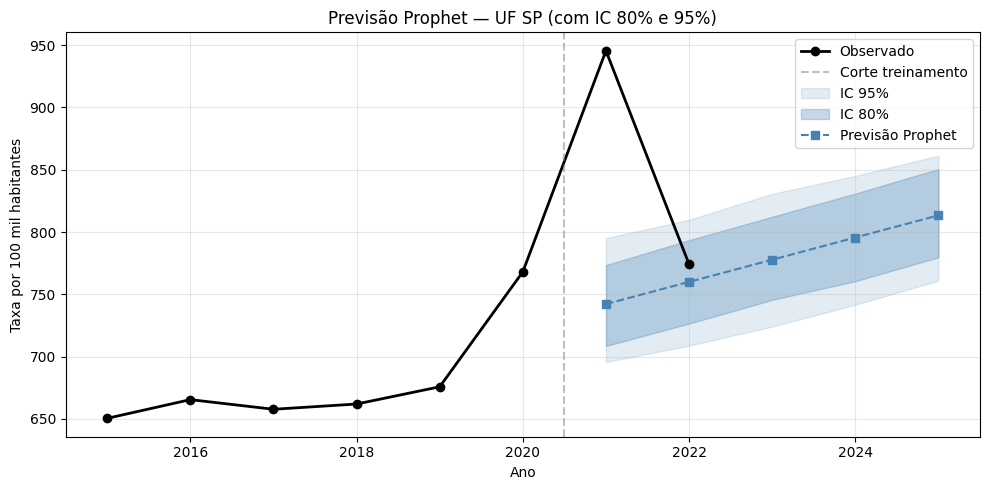

In [12]:
# Gráfico de ribbon para a UF de exemplo — série histórica + bandas CI 80% e 95%
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(df_uf_example['ds'].dt.year, df_uf_example['y'],
        'o-', color='black', label='Observado', linewidth=2)
ax.axvline(x=2020.5, color='gray', linestyle='--', alpha=0.5, label='Corte treinamento')

future_years = forecast_80['ds'].dt.year.values
ax.fill_between(future_years, forecast_95['yhat_lower'].values, forecast_95['yhat_upper'].values,
                alpha=0.15, color='steelblue', label='IC 95%')
ax.fill_between(future_years, forecast_80['yhat_lower'].values, forecast_80['yhat_upper'].values,
                alpha=0.30, color='steelblue', label='IC 80%')
ax.plot(future_years, forecast_80['yhat'].values,
        's--', color='steelblue', label='Previsão Prophet', linewidth=1.5)

ax.set_xlabel('Ano')
ax.set_ylabel('Taxa por 100 mil habitantes')
ax.set_title(f'Previsão Prophet — UF {example_uf} (com IC 80% e 95%)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Limitações

- **Validação em período de choque:** a janela 2021–2022 mede a reação a um evento externo, não
  a capacidade de prever tendência. Um backtest pré-pandemia (por exemplo, validação em
  2018–2019) precisaria de séries começando antes de 2015 para manter seis anos de treino.
- **Recorte geográfico:** apenas SP, RJ e MG; o runner de produção (`backend/ml/run_forecasting.py`)
  aplica a mesma metodologia a todos os municípios e grava em `forecast_resultados`.
- **Taxas brutas:** mudanças na estrutura etária ao longo dos anos entram na tendência.